# Pronóstico semanal de dengue por departamento

**Materia:** Aprendizaje Automático V, Maestría en Inteligencia Artificial Aplicada, Universidad ICESI

**Integrantes**

| Integrante | Código |
| --- | --- |
| Jairo Andrés Valencia | A00429914 |
| Juan Camilo Macías Navarrete | A00427476 |

El objetivo es pronosticar los casos de dengue de la semana siguiente en cada departamento. El error se mide con el error cuadrático medio (MSE): un departamento con muchos casos pesa más que uno con pocos.

Los casos observados van de 2007 a 2024. El entrenamiento usa 2007-2023 y la validación es el año 2024 completo. Las medias, las desviaciones y la mediana de cada departamento se calculan solo con el entrenamiento.

Se comparan cinco familias: perceptrón multicapa (MLP), red recurrente simple (RNN), LSTM, GRU y red convolucional temporal (TCN). En cada familia hay una variante base y una variante propia. La variante base sigue el material del curso. Ese material define el MLP (una capa de 64 unidades, sin apagado aleatorio y con ReLU a la salida) y el TCN (canales 32, 32, 64 y 64, filtro de tamaño 3 y apagado de 0,1). La RNN, la LSTM y la GRU no vienen definidas ahí, así que su variante base usa el tamaño del MLP. En el TCN de este cuaderno el bloque es convolución, ReLU y apagado, en las dos variantes; el detalle está en esa sección. La variante propia modifica las piezas que se indican en cada sección.


## Contenido

| Parte | Qué se hace |
| --- | --- |
| 1. Exploración | Tendencia anual, diferencia entre departamentos, forma dentro del año y correlación del clima con rezago |
| 2. MLP | Arquitectura de referencia y una variante |
| 3. RNN | La ventana se lee en orden, en dos tamaños |
| 4. LSTM y GRU | Celdas con memoria, cada una en dos tamaños |
| 5. TCN | Convolución que solo usa semanas ya ocurridas |
| 6. Comparación | Error de 2024 y serie observada contra el pronóstico |


## Preparación

La semilla fija el arranque de las redes. La diferencia de error queda así ligada a la arquitectura, no al azar del inicio. Si hay tarjeta gráfica se usa; si no, el mismo código corre en el procesador.


In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from torch import nn
from torch.utils.data import DataLoader, Dataset

# La semilla fija el arranque. Si cada red partiera distinto, la comparación mezclaría arquitectura con azar.
SEMILLA = 42
np.random.seed(SEMILLA)
torch.manual_seed(SEMILLA)

dispositivo = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Equipo:", "tarjeta gráfica" if dispositivo.type == "cuda" else "procesador")

# Los archivos están en la carpeta data/. Se busca desde el directorio actual hacia las carpetas superiores.
aqui = Path.cwd().resolve()
raiz = aqui
for carpeta in [aqui, *list(aqui.parents)[:6]]:
    if (carpeta / "data" / "train.parquet").exists():
        raiz = carpeta
        break
print("Datos en:", raiz / "data")


Equipo: tarjeta gráfica
Datos en: C:\Users\Usuario\Documents\ICESI\Maestria Inteligencia Artificial aplicada\SEMESTRE 2\Aprendizaje automatico 5\taller_final\data


## 1. Exploración de los datos

Se usan los años con casos observados, de 2007 a 2024. La semana 53 aparece solo en algunos años y se excluye, para que cada año quede en 52 semanas.


In [2]:
datos = pd.read_parquet(raiz / "data" / "train.parquet")
# La semana 53 solo existe en algunos años y desalinea el calendario. Se deja fuera.
datos = datos[datos.semana <= 52].copy()
datos = datos.sort_values(["id_departamento", "anio", "semana"]).reset_index(drop=True)

print("Filas y columnas:", datos.shape)
print("Años:", int(datos.anio.min()), "a", int(datos.anio.max()))
print("Departamentos:", datos.id_departamento.nunique())
print("Valores faltantes:", int(datos.isna().sum().sum()))
print("Casos: mínimo", float(datos.casos_dengue.min()), "mediana", float(datos.casos_dengue.median()), "máximo", float(datos.casos_dengue.max()))


Filas y columnas: (29016, 19)
Años: 2007 a 2024
Departamentos: 31
Valores faltantes: 0
Casos: mínimo 0.0 mediana 19.0 máximo 3219.0


Después de excluir la semana 53 quedan 29016 filas, 19 columnas y 31 departamentos, de 2007 a 2024, sin valores faltantes. La mediana es 19 casos y el máximo es 3219. La mayor parte de las semanas está cerca de la mediana. Unas pocas llegan a miles de casos y, como el error es cuadrático, van a dominar el MSE.


### Tendencia nacional

El promedio semanal de casos, con los 31 departamentos juntos, resume si el país estuvo en un año de brote o en un año de calma.


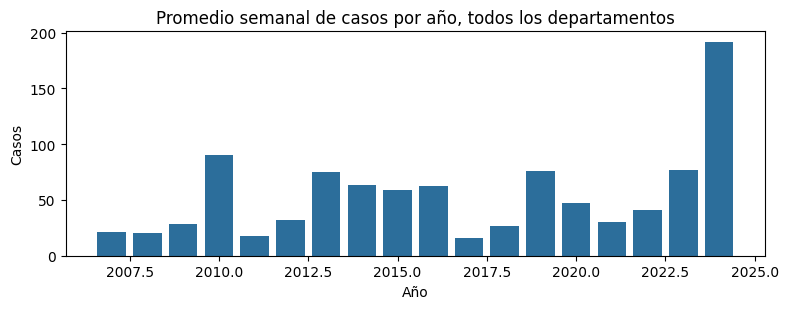

In [3]:
# El promedio nacional muestra los años de brote. El error cuadrático pesa más justo en esos años.
por_anio = datos.groupby("anio").casos_dengue.mean()
fig, ax = plt.subplots(figsize=(8, 3.2))
ax.bar(por_anio.index, por_anio.values, color="#2c6e9b")
ax.set_title("Promedio semanal de casos por año, todos los departamentos")
ax.set_xlabel("Año")
ax.set_ylabel("Casos")
fig.tight_layout()
plt.show()


El promedio semanal nacional pasa de 16 casos en 2017 y cerca de 20 en 2007-2008 a 91 en 2010 y 192 en 2024. El salto entre un año de calma y un año de brote es de un orden de magnitud. Un modelo ajustado al nivel típico se equivoca precisamente en los años que más pesan en el error.


### Diferencia entre departamentos

El promedio nacional esconde que los departamentos no comparten ni la escala ni el año del brote. Abajo se ven dos de muchos casos, uno intermedio y uno de muy pocos.


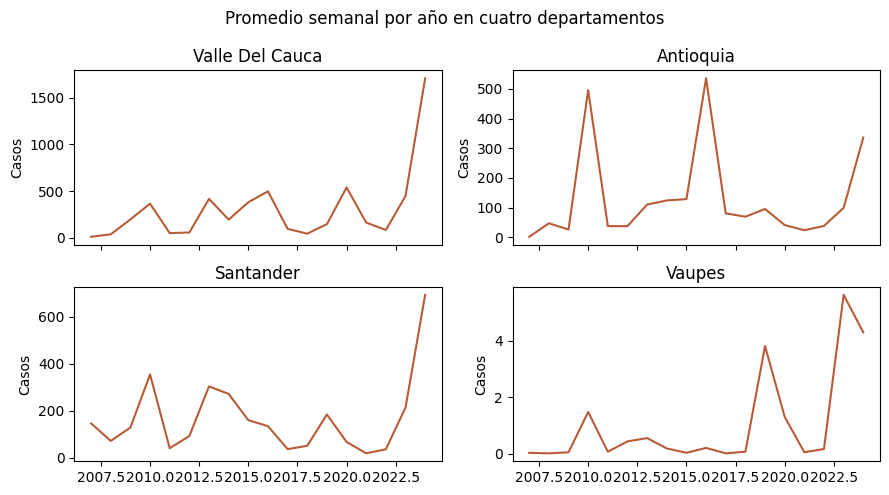

In [4]:
# Dos departamentos de muchos casos, uno intermedio y uno de muy pocos. La escala no es la misma.
elegidos = ["Valle Del Cauca", "Antioquia", "Santander", "Vaupes"]
fig, ejes = plt.subplots(2, 2, figsize=(9, 5), sharex=True)
for eje, nombre in zip(ejes.ravel(), elegidos):
    serie = datos[datos.departamento == nombre].groupby("anio").casos_dengue.mean()
    eje.plot(serie.index, serie.values, color="#b85c38")
    eje.set_title(nombre)
    eje.set_ylabel("Casos")
fig.suptitle("Promedio semanal por año en cuatro departamentos")
fig.tight_layout()
plt.show()


La escala no es la misma. En Valle del Cauca el promedio semanal mediano ronda 178 casos y en 2024 llega a cerca de 1700. En Vaupés la mediana está por debajo de 1 caso y el peor año no pasa de unas pocas unidades. Antioquia tiene su pico en 2016, no en 2024; Santander sí lo tiene en 2024. El año del brote no coincide entre departamentos, así que un solo nivel nacional no alcanza. Más adelante esa diferencia entra como la mediana histórica de cada departamento.


### Forma dentro del año

Además del salto entre años, los casos cambian según la semana. El promedio de cada semana, en todo el histórico, muestra si esa forma existe y qué tan grande es frente al salto entre años.


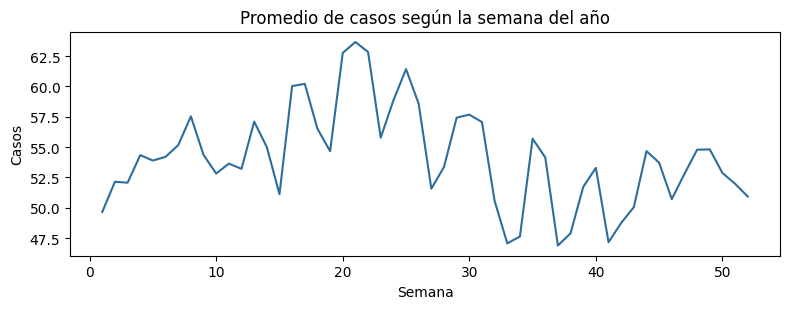

In [5]:
# El perfil por semana justifica el seno y el coseno: dentro del año hay forma, no es una línea plana.
perfil = datos.groupby("semana").casos_dengue.mean()
fig, ax = plt.subplots(figsize=(8, 3.2))
ax.plot(perfil.index, perfil.values, color="#2c6e9b")
ax.set_title("Promedio de casos según la semana del año")
ax.set_xlabel("Semana")
ax.set_ylabel("Casos")
fig.tight_layout()
plt.show()


El promedio por semana del año se mueve entre unos 47 y 64 casos, con el máximo alrededor de la semana 21. Hay forma dentro del año, y por eso más adelante entran el seno y el coseno de la semana. Esa oscilación es real y, al mismo tiempo, pequeña al lado del salto entre 2017 y 2024. El calendario explica una parte; no explica el brote.


### Clima y casos, con rezago

La correlación se calcula dentro de cada departamento: el clima de una semana contra los casos de cuatro semanas después. No se usa el clima de la misma semana que se quiere pronosticar.


               variable  correlacion
presion_superficial_hPa       -0.127
          punto_rocio_C       -0.098
             temp_max_C       -0.089
             temp_min_C       -0.085
           temp_media_C       -0.075
  evapotranspiracion_mm       -0.054
       precip_chirps_mm       -0.049
         viento_vel_m_s       -0.036
    humedad_suelo_capa1        0.007
  radiacion_solar_MJ_m2        0.002


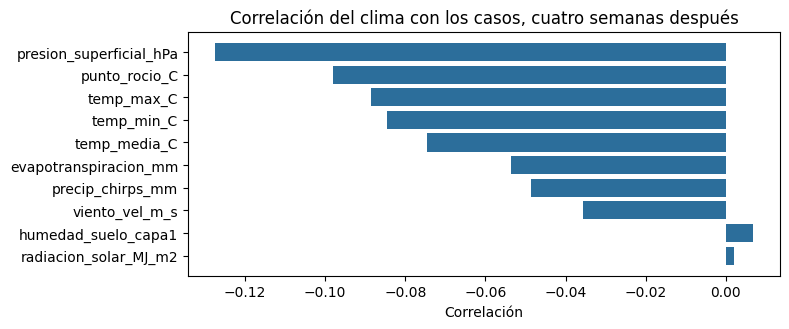

In [6]:
clima = [
    "precip_chirps_mm",
    "temp_media_C",
    "temp_min_C",
    "temp_max_C",
    "punto_rocio_C",
    "humedad_suelo_capa1",
    "evapotranspiracion_mm",
    "radiacion_solar_MJ_m2",
    "viento_vel_m_s",
    "presion_superficial_hPa",
]
# Cuatro semanas de rezago: el clima de una semana se compara con los casos de después, no con los de la misma semana.
rezago = 4
filas = []
for columna in clima:
    trozos_x = []
    trozos_y = []
    for _, grupo in datos.groupby("id_departamento"):
        grupo = grupo.sort_values(["anio", "semana"])
        trozos_x.append(grupo[columna].to_numpy(float)[:-rezago])
        trozos_y.append(grupo.casos_dengue.to_numpy(float)[rezago:])
    x = np.concatenate(trozos_x)
    y = np.concatenate(trozos_y)
    filas.append({"variable": columna, "correlacion": np.corrcoef(x, y)[0, 1]})

correlaciones = pd.DataFrame(filas).sort_values("correlacion", key=lambda s: s.abs(), ascending=False)
print(correlaciones.round(3).to_string(index=False))

fig, ax = plt.subplots(figsize=(8, 3.4))
ax.barh(correlaciones.variable[::-1], correlaciones.correlacion[::-1], color="#2c6e9b")
ax.set_title("Correlación del clima con los casos, cuatro semanas después")
ax.set_xlabel("Correlación")
fig.tight_layout()
plt.show()


Ninguna variable de clima pasa de 0,13 en valor absoluto. Las cuatro primeras son presión superficial (−0,127), punto de rocío (−0,098), temperatura máxima (−0,089) y temperatura mínima (−0,085). Humedad del suelo (0,007) y radiación (0,002) quedan en la práctica sin relación lineal con los casos.

El signo negativo no se lee como una causa directa del tipo “más calor, menos dengue”. Presión y temperatura también separan departamentos de altura de departamentos cálidos, y esa diferencia geográfica entra en la misma cuenta. El clima se usa como contexto de la ventana, no como la variable que por sí sola anuncia el brote. La señal fuerte sigue estando en los casos recientes del mismo departamento.


## Variables de entrada

Con la tabla anterior, cada ejemplo usa solo información anterior a la semana que se pronostica:

1. Presión superficial, punto de rocío, temperatura máxima y temperatura mínima. Son las cuatro correlaciones de mayor valor absoluto. La humedad del suelo y la radiación quedan fuera: su correlación es casi cero.
2. El seno y el coseno de la semana, para la forma dentro del año.
3. Los casos de las ocho semanas anteriores, que indican si el departamento ya venía en brote.
4. La mediana de casos del departamento en 2007-2023, dividida por la desviación de los casos. Separa un departamento de pocos casos de uno de muchos sin usar el año de validación.

No entra el identificador del departamento como una categoría, ni el clima de la semana a pronosticar, ni un estadístico calculado con 2024.

La ventana tiene 8 semanas. La referencia usa 5. Esas cinco no alcanzan a cubrir el rezago de cuatro semanas con el que se midió el clima, y dejan poco margen para el contagio de las semanas previas.


## Corte de entrenamiento y validación

El entrenamiento es 2007-2023 y la validación es 2024. Las medias y las desviaciones salen del entrenamiento y después se aplican a 2024. La primera ventana de 2024 puede incluir el cierre de 2023, porque esas semanas ya habían ocurrido. Ninguna ventana incluye una semana posterior a la que pronostica.

La convolución temporal rellena solo por la izquierda, por la misma restricción.


In [7]:
# Entran las cuatro de mayor correlación absoluta. No se eligen por el nombre, sino por la tabla anterior.
COLUMNAS_CLIMA = correlaciones.variable.head(4).tolist()
LONGITUD = 8
ENTRENAMIENTO_HASTA = 2023

entrenamiento = datos[datos.anio <= ENTRENAMIENTO_HASTA]
# Media y desviación solo con 2007-2023. Si entrara 2024, la escala conocería el año que se va a medir.
media = entrenamiento[COLUMNAS_CLIMA].mean()
desviacion = entrenamiento[COLUMNAS_CLIMA].std().replace(0, 1.0)
desviacion_casos = float(entrenamiento.casos_dengue.std())
nivel = entrenamiento.groupby("id_departamento").casos_dengue.median()

trabajo = datos.copy()
trabajo[COLUMNAS_CLIMA] = (trabajo[COLUMNAS_CLIMA] - media) / desviacion
trabajo["seno"] = np.sin(2 * np.pi * trabajo.semana / 52)
trabajo["coseno"] = np.cos(2 * np.pi * trabajo.semana / 52)
trabajo["nivel"] = trabajo.id_departamento.map(nivel).fillna(0.0) / desviacion_casos
trabajo["casos_escala"] = trabajo.casos_dengue / desviacion_casos

COLUMNAS = COLUMNAS_CLIMA + ["seno", "coseno", "nivel", "casos_escala"]
print("Variables de entrada:", COLUMNAS)
print("Desviación de casos, solo entrenamiento:", round(desviacion_casos, 1))


Variables de entrada: ['presion_superficial_hPa', 'punto_rocio_C', 'temp_max_C', 'temp_min_C', 'seno', 'coseno', 'nivel', 'casos_escala']
Desviación de casos, solo entrenamiento: 85.0


In [8]:
def construir_ventanas(tabla, columnas, longitud):
    # La entrada es lo ya visto. El objetivo es la semana siguiente y no entra en la ventana.
    entradas, objetivos, anios, deptos, semanas, ultimos = [], [], [], [], [], []
    for depto, grupo in tabla.groupby("id_departamento", sort=False):
        grupo = grupo.sort_values(["anio", "semana"])
        valores = grupo[columnas].to_numpy(np.float32)
        casos = grupo.casos_dengue.to_numpy(np.float32)
        for indice in range(longitud, len(grupo)):
            entradas.append(valores[indice - longitud:indice])
            objetivos.append(casos[indice])
            anios.append(int(grupo.anio.iloc[indice]))
            deptos.append(grupo.departamento.iloc[indice])
            semanas.append(int(grupo.semana.iloc[indice]))
            # La persistencia usa este valor: el último caso conocido, no el que se pronostica.
            ultimos.append(casos[indice - 1])
    return (
        np.stack(entradas),
        np.array(objetivos, dtype=np.float32),
        np.array(anios),
        np.array(deptos),
        np.array(semanas),
        np.array(ultimos, dtype=np.float32),
    )


entradas, objetivos, anios, deptos, semanas, ultimos = construir_ventanas(trabajo, COLUMNAS, LONGITUD)
es_entrenamiento = anios <= ENTRENAMIENTO_HASTA
es_validacion = anios == 2024
print("Ejemplos de entrenamiento:", int(es_entrenamiento.sum()))
print("Ejemplos de validación:", int(es_validacion.sum()))


Ejemplos de entrenamiento: 27156
Ejemplos de validación: 1612


Quedan 27156 ventanas de entrenamiento y 1612 de validación, una por cada departamento y semana de 2024. La desviación de los casos en 2007-2023 es 85. Con esa cifra se escalan los casos pasados y la mediana del departamento, para que un brote de miles de casos no entre a la red en otra unidad que el resto de las variables.


## Entrenamiento común

Todas las redes usan el mismo lote, la misma tasa y la misma parada. El error distinto se atribuye a la arquitectura, no a que una haya tenido más tiempo.

El ajuste común es: lote de 64, tasa de aprendizaje 0,0005, máximo 6 épocas, y parada si la validación no mejora durante dos épocas. La referencia del curso usa lote 32, tasa 0,001, 20 épocas en el MLP y 30 en el TCN. Aquí la tasa es más baja y el lote más grande porque unas pocas semanas de miles de casos dominan el MSE, y un paso grande mueve el ajuste de más. El gradiente se recorta a norma 1 por la misma razón.

El error de validación se calcula después de llevar a cero los pronósticos negativos. Un conteo de casos no puede ser negativo.


In [9]:
class Ventanas(Dataset):
    # El lote solo reparte ejemplos ya armados. No vuelve a calcular el pasado.
    def __init__(self, x, y):
        self.x = torch.tensor(x)
        self.y = torch.tensor(y)

    def __len__(self):
        return len(self.y)

    def __getitem__(self, indice):
        return self.x[indice], self.y[indice]


In [10]:
def entrenar(modelo, x_ent, y_ent, x_val, y_val, epocas=6, paciencia=2):
    # Misma semilla en cada red para que el lote barajado no cambie el resultado de una a otra.
    torch.manual_seed(SEMILLA)
    cargador = DataLoader(Ventanas(x_ent, y_ent), batch_size=64, shuffle=True)
    x_val_t = torch.tensor(x_val, device=dispositivo)
    y_val_t = torch.tensor(y_val, device=dispositivo)
    optimizador = torch.optim.Adam(modelo.parameters(), lr=0.0005)
    perdida = nn.MSELoss()
    mejor = float("inf")
    espera = 0
    estado = None
    for epoca in range(1, epocas + 1):
        modelo.train()
        acumulado = 0.0
        for lote_x, lote_y in cargador:
            lote_x = lote_x.to(dispositivo)
            lote_y = lote_y.to(dispositivo)
            optimizador.zero_grad()
            error = perdida(modelo(lote_x), lote_y)
            error.backward()
            # Un brote de miles de casos puede disparar el gradiente. Se recorta.
            nn.utils.clip_grad_norm_(modelo.parameters(), 1.0)
            optimizador.step()
            acumulado += error.item()
        modelo.eval()
        with torch.no_grad():
            # Un conteo no puede ser negativo. El error que se compara ya aplica ese recorte.
            pronostico = modelo(x_val_t).clamp(min=0)
            error_val = perdida(pronostico, y_val_t).item()
        print(f"Época {epoca}: entrenamiento {acumulado / len(cargador):.0f}, validación {error_val:.0f}")
        if error_val < mejor:
            mejor = error_val
            espera = 0
            estado = {clave: valor.detach().cpu().clone() for clave, valor in modelo.state_dict().items()}
        else:
            espera += 1
            if espera >= paciencia:
                break
    modelo.load_state_dict(estado)
    return mejor


In [11]:
def predecir(modelo, x):
    # Misma regla que en el entrenamiento: un conteo negativo se recorta a cero.
    modelo.eval()
    with torch.no_grad():
        tensor = torch.tensor(x, device=dispositivo)
        return modelo(tensor).clamp(min=0).cpu().numpy()


x_ent, y_ent = entradas[es_entrenamiento], objetivos[es_entrenamiento]
x_val, y_val = entradas[es_validacion], objetivos[es_validacion]
resultados = []
modelos = {}
print("Listo para entrenar.")


Listo para entrenar.


## 2. Perceptrón multicapa

La referencia tiene una capa oculta de 64 unidades, una activación ReLU, una capa de salida y otra ReLU sobre ese número. No tiene apagado aleatorio. La ventana se aplana, así que la red no distingue qué valor pertenece a qué semana.

La variante propia cambia cuatro piezas de esa arquitectura:

1. Dos capas ocultas en lugar de una.
2. 32 unidades en lugar de 64, para reducir la capacidad de memorizar semanas de brote.
3. Apagado aleatorio de 0,2.
4. Sin ReLU a la salida. Con esa ReLU, un pronóstico que cae a cero deja de recibir gradiente y no se ve si el modelo se quedó corto.

Las dos se entrenan con los mismos ejemplos.


In [12]:
class Perceptron(nn.Module):
    def __init__(self, n_variables, longitud, oculto, capas, apagado, relu_salida):
        super().__init__()
        piezas = []
        entrada = n_variables * longitud
        for _ in range(capas):
            piezas += [nn.Linear(entrada, oculto), nn.ReLU(), nn.Dropout(apagado)]
            entrada = oculto
        piezas.append(nn.Linear(entrada, 1))
        if relu_salida:
            piezas.append(nn.ReLU())
        self.red = nn.Sequential(*piezas)

    def forward(self, x):
        # Al aplanar se pierde qué número es de qué semana. Por eso esta red se compara aparte.
        return self.red(x.flatten(1)).squeeze(1)


variantes_mlp = {
    "MLP base": dict(oculto=64, capas=1, apagado=0.0, relu_salida=True),
    "MLP propio": dict(oculto=32, capas=2, apagado=0.2, relu_salida=False),
}
for nombre, ajuste in variantes_mlp.items():
    print()
    print(nombre)
    red = Perceptron(len(COLUMNAS), LONGITUD, **ajuste).to(dispositivo)
    error = entrenar(red, x_ent, y_ent, x_val, y_val)
    resultados.append({"modelo": nombre, "mse": error})
    modelos[nombre] = red



MLP base


Época 1: entrenamiento 7600, validación 101027


Época 2: entrenamiento 2836, validación 29293


Época 3: entrenamiento 1425, validación 21594


Época 4: entrenamiento 1258, validación 19439


Época 5: entrenamiento 1185, validación 18255


... (3 outputs left out)

Época 3: entrenamiento 1516, validación 20054


Época 4: entrenamiento 1391, validación 18385


Época 5: entrenamiento 1360, validación 17814


Época 6: entrenamiento 1287, validación 16473


Las dos redes bajan durante las seis épocas y no activan la parada. MLP base pasa de 101027 en la primera validación a 17113 en la sexta. MLP propio pasa de 53163 a 16473. Dos capas de 32 unidades, apagado de 0,2 y sin ReLU a la salida bajan el error en unos 640 puntos. Al cierre las dos siguen descendiendo, y la distancia entre ellas es corta frente al nivel del MSE.


## 3. Red recurrente simple

La referencia del curso no incluye una RNN. El punto de partida toma el tamaño del MLP de referencia: una capa de 64 unidades y sin apagado. La diferencia de fondo es el orden. La ventana no se aplana: la celda la recorre de la semana más antigua a la más reciente y el pronóstico sale del último estado.

La variante propia cambia tres piezas:

1. Dos capas en lugar de una, para combinar el rezago corto con el de toda la ventana.
2. 32 unidades en lugar de 64.
3. Apagado aleatorio de 0,2 entre las dos capas. Con una sola capa ese apagado no tiene efecto, por eso va junto con la segunda capa.


In [13]:
class RedRecurrente(nn.Module):
    def __init__(self, tipo, n_variables, oculto, capas, apagado):
        super().__init__()
        self.tipo = tipo
        celda = {"rnn": nn.RNN, "lstm": nn.LSTM, "gru": nn.GRU}[tipo]
        # Con una sola capa el apagado no se aplica. La variante de dos capas sí lo usa.
        self.celda = celda(
            n_variables,
            oculto,
            num_layers=capas,
            batch_first=True,
            dropout=apagado if capas > 1 else 0.0,
        )
        self.cabeza = nn.Linear(oculto, 1)

    def forward(self, x):
        _, estado = self.celda(x)
        # La LSTM devuelve memoria y estado. El pronóstico usa el estado de la última capa.
        ultimo = estado[0][-1] if self.tipo == "lstm" else estado[-1]
        return self.cabeza(ultimo).squeeze(1)


variantes_rnn = {
    "RNN base": dict(oculto=64, capas=1, apagado=0.0),
    "RNN propia": dict(oculto=32, capas=2, apagado=0.2),
}
for nombre, ajuste in variantes_rnn.items():
    print()
    print(nombre)
    red = RedRecurrente("rnn", len(COLUMNAS), **ajuste).to(dispositivo)
    error = entrenar(red, x_ent, y_ent, x_val, y_val)
    resultados.append({"modelo": nombre, "mse": error})
    modelos[nombre] = red



RNN base


Época 1: entrenamiento 8645, validación 159002


Época 2: entrenamiento 7783, validación 154383


Época 3: entrenamiento 7085, validación 151150


Época 4: entrenamiento 6478, validación 148215


Época 5: entrenamiento 6071, validación 145607


... (3 outputs left out)

Época 3: entrenamiento 7941, validación 156589


Época 4: entrenamiento 7621, validación 154334


Época 5: entrenamiento 7331, validación 152716


Época 6: entrenamiento 6823, validación 151261


RNN base cierra en 143371 y RNN propia en 151261. El error baja en todas las épocas, desde cerca de 160000, y en la sexta todavía no se ha estabilizado. Aun así queda un orden de magnitud por encima del MLP. La variante de dos capas, 32 unidades y apagado de 0,2 termina peor que la de una capa. Con seis épocas ese cambio no ayuda. La ventana se lee en orden, pero el estado no llega a representar la magnitud de los casos.


## 4. LSTM y GRU

La RNN simple junta todo el pasado en un solo estado, y el comienzo de la ventana pesa poco. LSTM y GRU guardan una memoria aparte de ese estado. Tampoco vienen en la referencia del curso. El punto de partida vuelve a ser una capa de 64 unidades sin apagado, esta vez con la celda de memoria.

Cada familia tiene una variante con cuatro cambios:

1. La celda de memoria, que la referencia no tiene.
2. Dos capas en lugar de una.
3. 48 unidades en lugar de 64.
4. Apagado aleatorio de 0,3.

LSTM y GRU se entrenan por separado. No se asume de antemano cuál de las dos conserva mejor el nivel de esta serie.


In [14]:
# LSTM y GRU comparten la misma pareja de tamaños, para que la diferencia sea la celda y no el ancho.
variantes_memoria = {
    "LSTM base": ("lstm", dict(oculto=64, capas=1, apagado=0.0)),
    "LSTM propio": ("lstm", dict(oculto=48, capas=2, apagado=0.3)),
    "GRU base": ("gru", dict(oculto=64, capas=1, apagado=0.0)),
    "GRU propio": ("gru", dict(oculto=48, capas=2, apagado=0.3)),
}
for nombre, (tipo, ajuste) in variantes_memoria.items():
    print()
    print(nombre)
    red = RedRecurrente(tipo, len(COLUMNAS), **ajuste).to(dispositivo)
    error = entrenar(red, x_ent, y_ent, x_val, y_val)
    resultados.append({"modelo": nombre, "mse": error})
    modelos[nombre] = red



LSTM base


Época 1: entrenamiento 8632, validación 158874


Época 2: entrenamiento 7623, validación 154607


Época 3: entrenamiento 6929, validación 150918


Época 4: entrenamiento 6367, validación 147573


Época 5: entrenamiento 5917, validación 144696


... (15 outputs left out)

Época 3: entrenamiento 7361, validación 153635


Época 4: entrenamiento 6859, validación 150817


Época 5: entrenamiento 6444, validación 148338


Época 6: entrenamiento 6086, validación 145979


Las cuatro curvas bajan en las seis épocas y ninguna se detiene antes. La mejor es GRU base, con 141707, y la peor es LSTM propio, con 146038. LSTM base queda en 142179 y GRU propio en 145979. Están al lado de la RNN simple y lejos del MLP. Sumar la memoria no mueve el error de forma apreciable con estas seis épocas. Las variantes de dos capas, 48 unidades y apagado de 0,3 quedan por encima de las de una sola capa.


## 5. Red convolucional temporal

La referencia tiene cuatro bloques, con canales 32, 32, 64 y 64, filtro de tamaño 3 y apagado de 0,1. En el material del curso cada bloque lleva además norma de grupo y una conexión residual. En este cuaderno el bloque, para las dos variantes, es convolución, ReLU y apagado. El relleno se hace solo a la izquierda: un relleno simétrico usaría semanas posteriores, entre ellas la semana que se quiere pronosticar.

La variante propia, frente a la variante base de este cuaderno, cambia tres piezas:

1. Tres bloques en lugar de cuatro, con canales 16, 16 y 32.
2. Filtro de tamaño 2 en lugar de 3.
3. Apagado aleatorio de 0,2 en lugar de 0,1.

Frente al material del curso hay un cambio más, compartido por las dos variantes: el bloque no usa norma de grupo ni conexión residual. La comparación de error mide los tres cambios de la lista, no ese cambio compartido.

Con dilataciones 1, 2 y 4 y filtro de tamaño 2, la variante propia alcanza justo las 8 semanas de la ventana. La referencia, con filtro 3 y cuatro dilataciones, tiene un alcance mayor que esas 8 semanas. El tramo que se sale de la ventana ve ceros del relleno, no semanas reales.


In [15]:
class ConvolucionCausal(nn.Module):
    def __init__(self, entrada, salida, nucleo, dilatacion):
        super().__init__()
        self.izquierda = (nucleo - 1) * dilatacion
        self.conv = nn.Conv1d(entrada, salida, nucleo, dilation=dilatacion)

    def forward(self, x):
        # Relleno solo a la izquierda: la semana que se pronostica no entra al cálculo.
        return self.conv(nn.functional.pad(x, (self.izquierda, 0)))


class RedTCN(nn.Module):
    def __init__(self, n_variables, canales, nucleo, apagado):
        super().__init__()
        piezas = []
        entrada = n_variables
        dilatacion = 1
        for salida in canales:
            piezas += [
                ConvolucionCausal(entrada, salida, nucleo, dilatacion),
                nn.ReLU(),
                nn.Dropout(apagado),
            ]
            entrada = salida
            # La dilatación se duplica para cubrir la ventana sin alargar el filtro.
            dilatacion *= 2
        self.bloques = nn.Sequential(*piezas)
        self.cabeza = nn.Linear(canales[-1], 1)

    def forward(self, x):
        oculto = self.bloques(x.transpose(1, 2))
        # El último paso es la semana justo anterior a la que se pronostica.
        return self.cabeza(oculto[:, :, -1]).squeeze(1)


In [16]:
# La primera variante conserva canales y filtro de la referencia. La segunda los reduce.
variantes_tcn = {
    "TCN base": dict(canales=[32, 32, 64, 64], nucleo=3, apagado=0.1),
    "TCN propio": dict(canales=[16, 16, 32], nucleo=2, apagado=0.2),
}
for nombre, ajuste in variantes_tcn.items():
    print()
    print(nombre)
    red = RedTCN(len(COLUMNAS), **ajuste).to(dispositivo)
    error = entrenar(red, x_ent, y_ent, x_val, y_val)
    resultados.append({"modelo": nombre, "mse": error})
    modelos[nombre] = red



TCN base


Época 1: entrenamiento 3608, validación 21313


Época 2: entrenamiento 1356, validación 17950


Época 3: entrenamiento 1194, validación 14557


Época 4: entrenamiento 1102, validación 12630


Época 5: entrenamiento 1066, validación 12552


... (3 outputs left out)

Época 3: entrenamiento 1621, validación 20843


Época 4: entrenamiento 1545, validación 20054


Época 5: entrenamiento 1537, validación 20290


Época 6: entrenamiento 1459, validación 19770


TCN base baja de 21313 en la primera época a 11265 en la sexta, y en la última época la validación sigue mejorando. TCN propio termina en 19770. En su época 5 la validación sube a 20290 y en la 6 vuelve a bajar, sin alcanzar a TCN base. Menos canales, un filtro más corto y más apagado suben el error en cerca de 8500 puntos. Las dos variantes usan el mismo bloque, así que esa diferencia no viene de la conexión residual. En la primera época TCN base ya está en 21313, un nivel al que el MLP solo se acerca al final del entrenamiento.


## 6. Comparación en 2024

La persistencia pronostica la semana siguiente con los casos de la semana que acaba de terminar. Es el piso de la comparación: si una red no baja ese error, el clima y el calendario no están aportando por encima de repetir el último valor.

Se toma como modelo la red de menor MSE en 2024. El gráfico compara la serie observada con ese pronóstico en Valle del Cauca, donde los casos son muchos, y en Vaupés, donde son muy pocos.


Persistencia: 32248
     modelo      mse
   TCN base  11265.0
 MLP propio  16473.0
   MLP base  17113.0
 TCN propio  19770.0
   GRU base 141707.0
  LSTM base 142179.0
   RNN base 143371.0
 GRU propio 145979.0
LSTM propio 146038.0
 RNN propia 151261.0
Red elegida: TCN base con MSE 11265
Le gana a la persistencia.


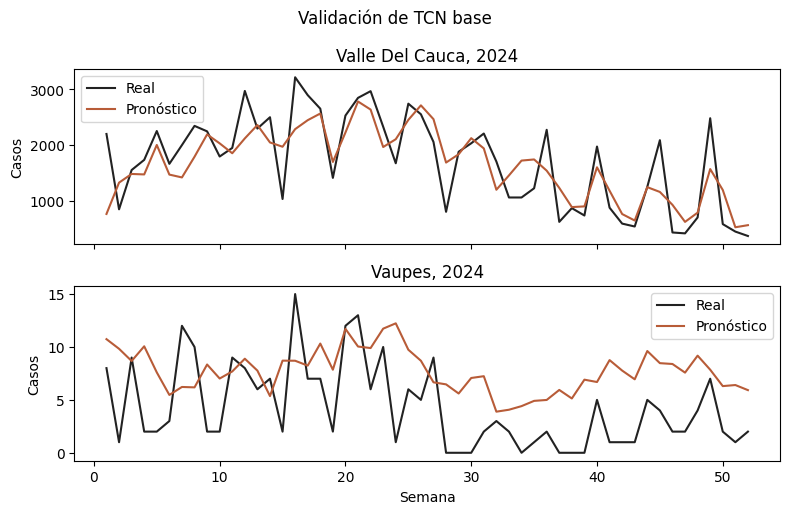

In [17]:
# La persistencia repite el último caso visto. Si la red no le baja el error, no está aportando.
mse_persistencia = float(np.mean((y_val - ultimos[es_validacion]) ** 2))
tabla = pd.DataFrame(resultados).sort_values("mse").reset_index(drop=True)
print("Persistencia:", round(mse_persistencia))
print(tabla.round(0).to_string(index=False))

ganador = tabla.iloc[0]
print("Red elegida:", ganador.modelo, "con MSE", round(ganador.mse))
if ganador.mse < mse_persistencia:
    print("Le gana a la persistencia.")
else:
    print("No le gana a la persistencia. La red sigue siendo la mejor de las arquitecturas, pero el salto de una semana todavía explica gran parte del brote.")

pronostico = predecir(modelos[ganador.modelo], x_val)
reales = pd.DataFrame({
    "departamento": deptos[es_validacion],
    "semana": semanas[es_validacion],
    "real": y_val,
    "pronostico": pronostico,
})

# Un departamento de muchos casos y uno de pocos, para no juzgar el modelo solo por Valle.
fig, ejes = plt.subplots(2, 1, figsize=(8, 5.2), sharex=True)
for eje, nombre in zip(ejes, ["Valle Del Cauca", "Vaupes"]):
    parte = reales[reales.departamento == nombre].sort_values("semana")
    eje.plot(parte.semana, parte.real, label="Real", color="#222222")
    eje.plot(parte.semana, parte.pronostico, label="Pronóstico", color="#b85c38")
    eje.set_title(nombre + ", 2024")
    eje.set_ylabel("Casos")
    eje.legend()
ejes[-1].set_xlabel("Semana")
fig.suptitle("Validación de " + ganador.modelo)
fig.tight_layout()
plt.show()


La tabla ordena las diez redes por el MSE de 2024. TCN base queda primero, con 11265, por debajo de la persistencia (32248). MLP propio es el segundo, con 16473. Desde GRU base el error salta a más de 140000: la RNN, la LSTM y la GRU quedan por encima de repetir la semana anterior.

El gráfico corresponde a TCN base. En Valle del Cauca la serie se mueve entre unos 500 y más de 3000 casos. El pronóstico sigue ese nivel y suaviza los picos: cuando la serie supera los 3000, el pronóstico se queda por debajo. En Vaupés la escala es de 0 a 15. El pronóstico se mueve entre 4 y 12 y no acompaña las semanas en cero de la segunda mitad del año, ni los saltos cortos de la primera. Separa las dos escalas. Dentro de la escala pequeña se queda en un valor intermedio.


## Conclusión

En 2024 el menor error es el de TCN base: 11265. Siguen MLP propio (16473) y MLP base (17113). TCN propio sube a 19770. La persistencia, que repite la semana anterior, queda en 32248. La RNN, la LSTM y la GRU cierran entre 141707 y 151261.

TCN base reduce el error de la persistencia a cerca de un tercio. La semana anterior ya contiene buena parte del brote, y la convolución sobre las ocho semanas previas corrige lo que esa repetición no alcanza. En Valle del Cauca el pronóstico sigue el nivel del brote y recorta los picos. En Vaupés distingue la escala, de decenas de casos contra miles, pero se queda por encima de las semanas en cero. Los casos recientes y la mediana histórica del departamento separan esas dos escalas.

En el MLP, los cuatro cambios de arquitectura bajan el error de 17113 a 16473. La mejora es pequeña: las dos curvas siguen descendiendo en la época 6. En la RNN, la LSTM y la GRU pasa lo contrario. Dos capas y apagado aleatorio dejan un error mayor que el de la variante base. Con las mismas seis épocas esas redes todavía bajan en cada época, y se quedan cerca de 140000. El estado no ha cargado la magnitud de los casos.

2024 es el año de mayor promedio del histórico: cerca de 192 casos por semana, frente a 16 en 2017. El MSE de este corte es alto porque los brotes pesan al cuadrado. Describe un año de brote, no un año de calma.

El modelo elegido es TCN base. Es el de menor error en 2024 y baja de forma clara el error de repetir la semana anterior. MLP propio queda segundo: aplana la ventana y aun así supera a la persistencia. La RNN, la LSTM y la GRU no: con este entrenamiento su error sigue un orden de magnitud por encima.
